# 06. RNN — 순서가 있는 데이터

MLP는 입력 길이가 고정되어 있고 순서 개념이 없다. RNN은 토큰을 **하나씩 차례로** 읽으면서 **은닉 상태 $h$** 에 지금까지의 정보를 누적한다.

$$h_t = \tanh(x_t W_{ih}^\top + b_{ih} + h_{t-1} W_{hh}^\top + b_{hh})$$

모든 시점에서 **같은 가중치**를 쓰므로 길이에 상관없이 처리할 수 있다.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(0)

## 1. RNN을 손으로 펼쳐서 `nn.RNN`과 비교

In [2]:
B, T, D, H = 2, 5, 3, 4                 # 배치, 길이, 입력 차원, 은닉 차원
x = torch.randn(B, T, D)
rnn = nn.RNN(input_size=D, hidden_size=H, batch_first=True)

W_ih, W_hh = rnn.weight_ih_l0, rnn.weight_hh_l0     # (H, D), (H, H)
b_ih, b_hh = rnn.bias_ih_l0, rnn.bias_hh_l0

h = torch.zeros(B, H)
outs = []
for t in range(T):                                  # 시점마다 같은 가중치
    h = torch.tanh(x[:, t] @ W_ih.T + b_ih + h @ W_hh.T + b_hh)
    outs.append(h)
manual = torch.stack(outs, dim=1)                   # (B, T, H)

out, h_n = rnn(x)
print("out:", out.shape, "| h_n:", h_n.shape)
print("모든 시점 출력 일치:", torch.allclose(manual, out, atol=1e-6))
print("마지막 은닉 일치   :", torch.allclose(h, h_n[0], atol=1e-6))

out: torch.Size([2, 5, 4]) | h_n: torch.Size([1, 2, 4])
모든 시점 출력 일치: True
마지막 은닉 일치   : True


### 입출력 shape 정리 (`batch_first=True`)

| | shape | 의미 |
| --- | --- | --- |
| 입력 | `(B, T, D)` | |
| `output` | `(B, T, H × 방향 수)` | 마지막 층의 **모든 시점** 은닉 상태 |
| `h_n` | `(층 수 × 방향 수, B, H)` | 모든 층의 **마지막 시점** 은닉 상태 |
| LSTM | `output, (h_n, c_n)` | 셀 상태 `c`가 추가됨 |

In [3]:
x = torch.randn(2, 5, 3)
for name, layer in [("RNN", nn.RNN(3, 4, batch_first=True)),
                    ("GRU 2층", nn.GRU(3, 4, num_layers=2, batch_first=True)),
                    ("LSTM 양방향", nn.LSTM(3, 4, batch_first=True, bidirectional=True))]:
    out, state = layer(x)
    if isinstance(state, tuple):
        print(f"{name:10s} out {tuple(out.shape)}  h_n {tuple(state[0].shape)}  c_n {tuple(state[1].shape)}")
    else:
        print(f"{name:10s} out {tuple(out.shape)}  h_n {tuple(state.shape)}")

RNN        out (2, 5, 4)  h_n (1, 2, 4)
GRU 2층     out (2, 5, 4)  h_n (2, 2, 4)
LSTM 양방향   out (2, 5, 8)  h_n (2, 2, 4)  c_n (2, 2, 4)


## 2. 글자 단위 언어 모델 (Char-RNN)

과제: 지금까지의 글자를 보고 **다음 글자를 맞힌다**. GPT와 같은 과제를 글자 단위 RNN으로 푸는 것이다.

In [4]:
import contextlib, io, codecs
with contextlib.redirect_stdout(io.StringIO()):   # import this 는 화면에 출력하므로 숨김
    import this
text = codecs.decode(this.s, "rot13")             # 파이썬에 내장된 'The Zen of Python' 원문
print(len(text), "글자")
print(text[:180])

856 글자
The Zen of Python, by Tim Peters

Beautiful is better than ugly.
Explicit is better than implicit.
Simple is better than complex.
Complex is better than complicated.
Flat is better


In [5]:
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
V = len(chars)
data = torch.tensor([stoi[c] for c in text])

SEQ_LEN = 64
chunks = data.unfold(0, SEQ_LEN + 1, 1)            # (N, 65) : stride 1 슬라이딩 윈도우
X, Y = chunks[:, :-1], chunks[:, 1:]               # 입력 / 한 칸 민 정답
loader = DataLoader(TensorDataset(X, Y), batch_size=64, shuffle=True)
print("어휘:", V, "| 샘플:", X.shape)

어휘: 45 | 샘플: torch.Size([792, 64])


In [6]:
class CharRNN(nn.Module):
    def __init__(self, vocab_size, emb_dim=32, hidden=128, cell="lstm"):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim)
        rnn_cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell]
        self.rnn = rnn_cls(emb_dim, hidden, batch_first=True)
        self.head = nn.Linear(hidden, vocab_size)

    def forward(self, x, state=None):          # x: (B, T)
        out, state = self.rnn(self.emb(x), state)  # (B, T, H)
        return self.head(out), state               # logits (B, T, V)


def train_lm(model, epochs, lr=3e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        total = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            logits, _ = model(xb)
            loss = F.cross_entropy(logits.reshape(-1, V), yb.reshape(-1))   # (B*T, V) vs (B*T,)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)              # RNN은 기울기 폭주 방지용 클리핑을 흔히 씀
            optimizer.step()
            total += loss.item()
        if epoch % 5 == 0 or epoch == epochs - 1:
            print(f"  epoch {epoch:2d}  loss {total / len(loader):.3f}")
    return total / len(loader)


torch.manual_seed(0)
model = CharRNN(V, cell="lstm")
train_lm(model, epochs=20)

  epoch  0  loss 3.334


  epoch  5  loss 1.320


  epoch 10  loss 0.378


  epoch 15  loss 0.176


  epoch 19  loss 0.131


0.13123073027684137

### 생성: 한 글자씩 뽑고, 그 글자를 다시 입력으로

RNN은 은닉 상태 `state`를 넘겨 주면 **이전 글자를 다시 계산할 필요가 없다**.
`temperature`가 낮으면 확률이 높은 글자 위주로 안전하게, 높으면 다양하게 뽑는다.

In [7]:
@torch.no_grad()
def generate(model, prompt, n=200, temperature=1.0):
    model.eval()
    x = torch.tensor([[stoi[c] for c in prompt]])
    logits, state = model(x)                          # 프롬프트 전체를 먼저 읽음
    out = prompt
    for _ in range(n):
        probs = torch.softmax(logits[0, -1] / temperature, dim=-1)
        nxt = torch.multinomial(probs, 1)             # 확률에 따라 샘플링
        out += itos[nxt.item()]
        logits, state = model(nxt.view(1, 1), state)  # 새 글자 하나 + 이전 상태
    return out

torch.manual_seed(0)
print(generate(model, "Beautiful is", temperature=0.5))
print("-" * 60)
print(generate(model, "Beautiful is", temperature=1.2))

Beautiful is better than ugly.
Explicit is better than implicit.
Simple is better than complex.
Complex is better than complicated.
Flat is better than nested.
Sparse is better than dense.
Readability counts.
Spe
------------------------------------------------------------
Beautiful is better than ugly.
Explicit is better than implicit.
Eexple io bad isa better thas pores shanlt sy one sse explicictlid beat ou's that is hambiguity, refuse the tempttef ant omnlen.
Int is better than


### RNN / GRU / LSTM 비교

같은 조건에서 손실을 비교한다. LSTM과 GRU는 **게이트**로 무엇을 기억하고 잊을지 조절해서, 기본 RNN보다 학습이 잘 된다.

In [8]:
for cell in ["rnn", "gru", "lstm"]:
    torch.manual_seed(0)
    print(cell)
    train_lm(CharRNN(V, cell=cell), epochs=10)

rnn


  epoch  0  loss 3.071


  epoch  5  loss 0.699


  epoch  9  loss 0.212
gru


  epoch  0  loss 3.227


  epoch  5  loss 0.982


  epoch  9  loss 0.217
lstm


  epoch  0  loss 3.334


  epoch  5  loss 1.320


  epoch  9  loss 0.480


## 3. RNN의 한계: 기울기 소실

마지막 출력의 기울기를 시점별 입력까지 거꾸로 따라가 보면, 기본 RNN에서는 **먼 과거로 갈수록 기울기가 급격히 작아진다**.
매 시점마다 $W_{hh}$와 tanh 미분(≤1)이 곱해지기 때문이다. 그래서 오래전 정보를 학습하기 어렵다.

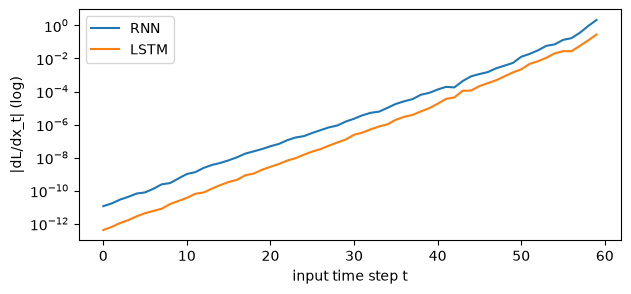

In [9]:
T = 60
torch.manual_seed(0)
x = torch.randn(1, T, 8, requires_grad=True)
plt.figure(figsize=(7, 3))
for name, layer in [("RNN", nn.RNN(8, 32, batch_first=True)), ("LSTM", nn.LSTM(8, 32, batch_first=True))]:
    x.grad = None
    out, _ = layer(x)
    out[0, -1].sum().backward()                      # 마지막 시점 출력에서 역전파
    grad_norm = x.grad[0].norm(dim=-1)               # 시점별 입력 기울기 크기
    plt.semilogy(grad_norm.detach(), label=name)
plt.xlabel("input time step t")
plt.ylabel("|dL/dx_t| (log)")
plt.legend()
plt.show()

### RNN의 남은 문제 → 다음 노트북

1. **순차 계산**: $h_t$를 구하려면 $h_{t-1}$이 있어야 하므로 시점끼리 병렬 처리가 안 된다.
2. **병목**: 문장 전체 정보가 고정 크기 벡터 $h$ 하나에 담겨야 한다.

2번을 해결한 것이 **Attention** (07), 1번까지 해결한 것이 **Transformer** (08, 09) 이다.